Файл: /content/photo_2024-07-15_16-42-02.jpg
Размер растра (H, W, C): (1280, 960, 3)
Размер файла: 202163 байт


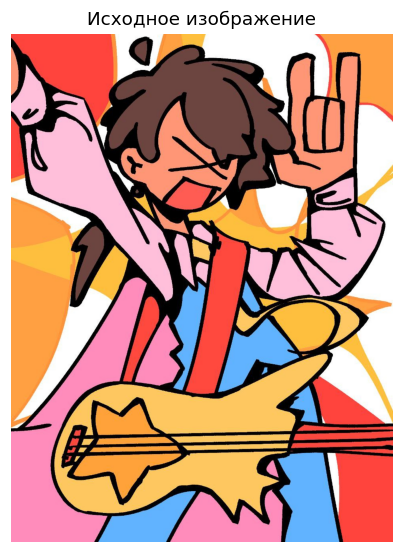

Форма U первого канала: (1280, 960)
Число сингулярных чисел: 960
Первые 10 сингулярных чисел красного канала:
[212272.2589  35398.0033  29193.1027  28026.9872  23883.38    21443.4871
  20244.1887  18692.8368  17972.7706  17413.7466]

    r |            MSE |   PSNR, дБ |   Байт (float32) |   Сжатие
----------------------------------------------------------------------
    1 |       6960.150 |       9.70 |            26892 |   137.08
    5 |       4338.777 |      11.76 |           134460 |    27.42
   10 |       3103.581 |      13.21 |           268920 |    13.71
   30 |       1332.141 |      16.89 |           806760 |     4.57
   60 |        554.759 |      20.69 |          1613520 |     2.28
  120 |        206.530 |      24.98 |          3227040 |     1.14
  960 |          0.000 |     168.13 |         25816320 |     0.14


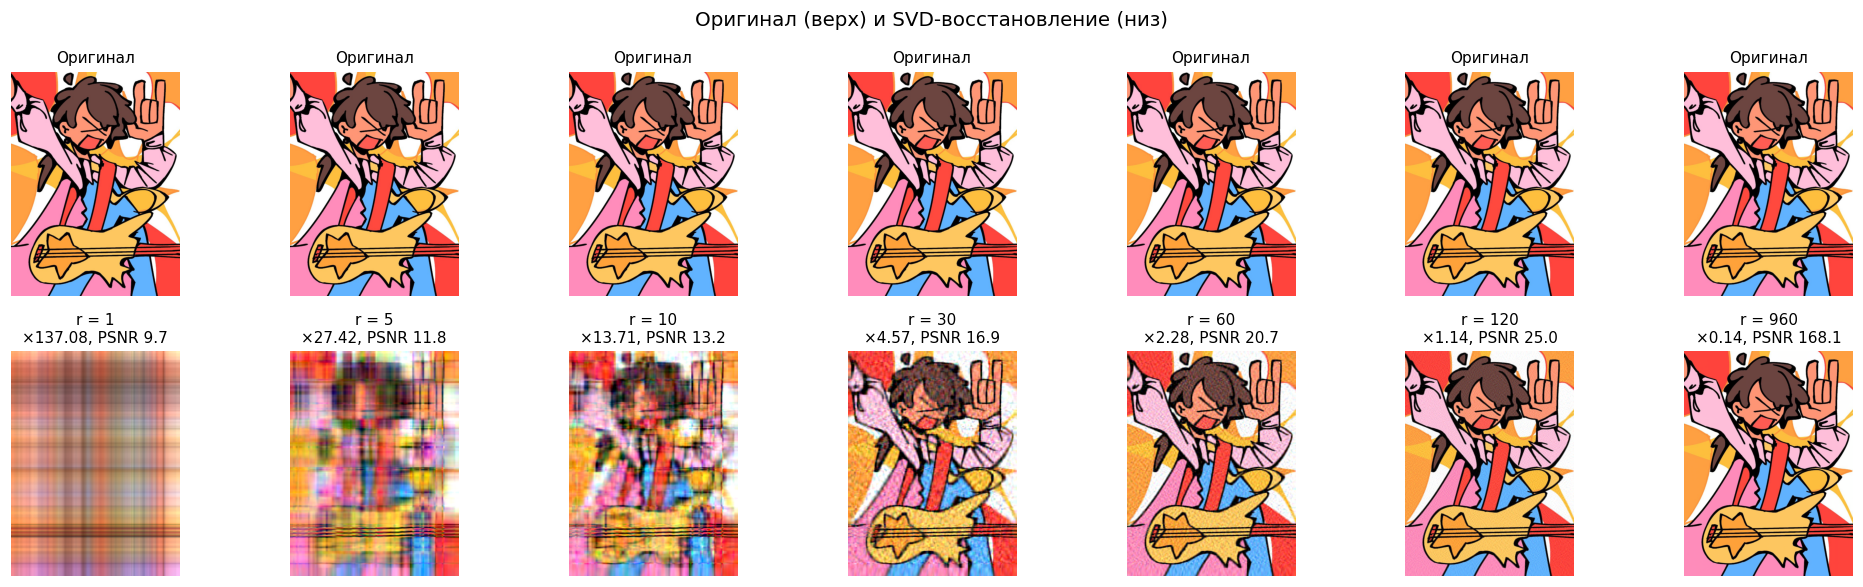

Сводная таблица по рангам
    r |          MSE |   PSNR, дБ |  Сжатие, раз
--------------------------------------------------
    1 |     6960.150 |       9.70 |       137.08
    5 |     4338.777 |      11.76 |        27.42
   10 |     3103.581 |      13.21 |        13.71
   30 |     1332.141 |      16.89 |         4.57
   60 |      554.759 |      20.69 |         2.28
  120 |      206.530 |      24.98 |         1.14
  960 |        0.000 |     168.13 |         0.14


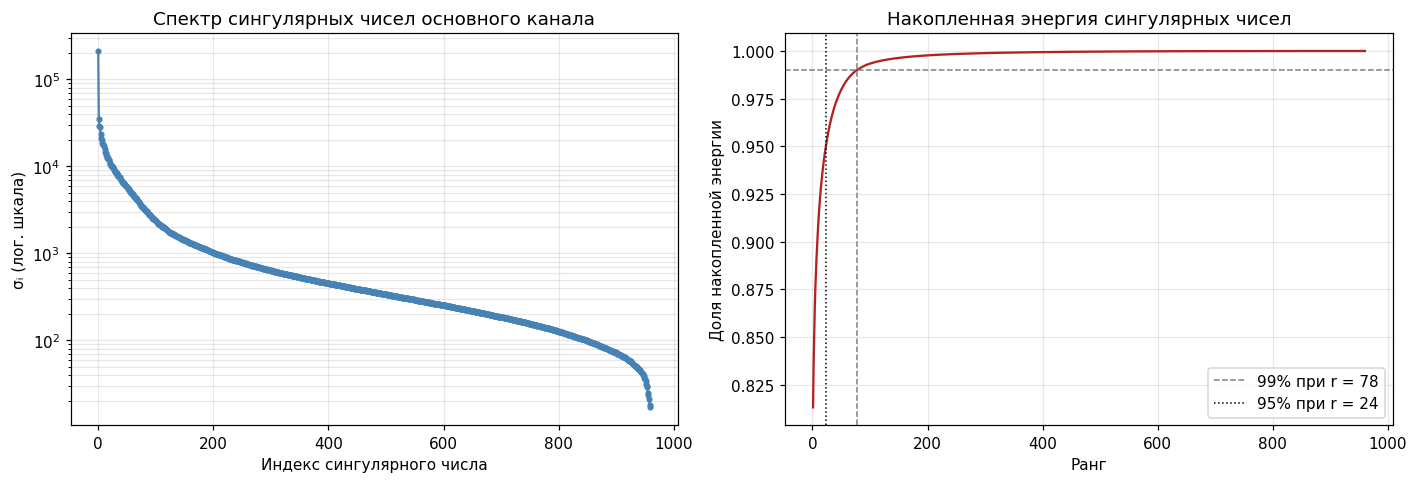

Для 95% энергии достаточно r = 24, для 99% — r = 78.


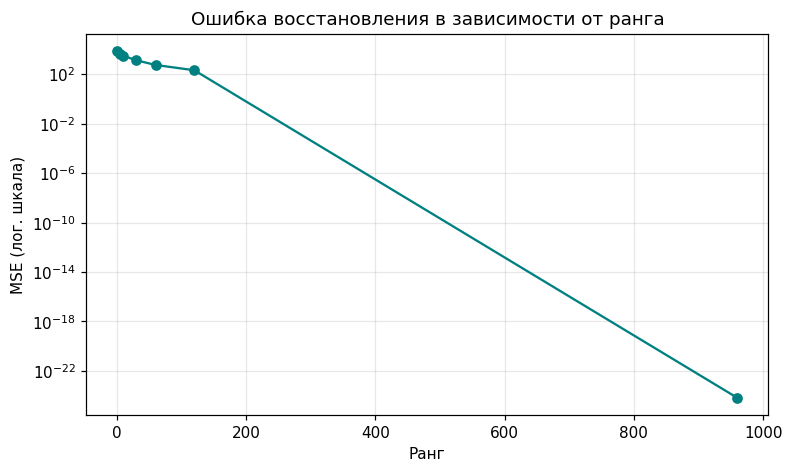

Файлы сохранены в: /content/svd_output


In [6]:
"""
Лабораторная работа: сжатие растрового изображения методом SVD.
"""
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

np.set_printoptions(precision=4, suppress=True)
plt.rcParams["figure.dpi"] = 110

IMAGE_PATH = Path("/content/photo_2024-07-15_16-42-02.jpg")

# Куда складывать результаты (создастся автоматически).
OUT_DIR = Path("svd_output")
OUT_DIR.mkdir(exist_ok=True)


# =====================================================================
# Шаг 1. Чтение растрового файла
# =====================================================================
if not IMAGE_PATH.exists():
    raise FileNotFoundError(
        f"Не найден файл {IMAGE_PATH.resolve()}. "
    )

img = Image.open(IMAGE_PATH).convert("RGB")
raster = np.asarray(img, dtype=np.uint8)
H, W, C = raster.shape
print(f"Файл: {IMAGE_PATH}")
print(f"Размер растра (H, W, C): {raster.shape}")
print(f"Размер файла: {IMAGE_PATH.stat().st_size} байт")

plt.figure(figsize=(8, 6))
plt.imshow(raster)
plt.title("Исходное изображение")
plt.axis("off")
plt.show()


# =====================================================================
# Шаг 2. SVD каждого цветового канала
# =====================================================================
raster_f = raster.astype(np.float64)
channel_svd = []
for c in range(C):
    U, s, Vt = np.linalg.svd(raster_f[:, :, c], full_matrices=False)
    channel_svd.append((U, s, Vt))

max_rank = min(H, W)
print(f"Форма U первого канала: {channel_svd[0][0].shape}")
print(f"Число сингулярных чисел: {channel_svd[0][1].size}")
print("Первые 10 сингулярных чисел красного канала:")
print(channel_svd[0][1][:10])


# =====================================================================
# Шаг 3. Восстановление изображения для разных рангов
# =====================================================================
def restore(rank: int) -> np.ndarray:
    """Восстанавливает RGB-картинку по первым rank сингулярным числам."""
    chans = []
    for U, s, Vt in channel_svd:
        # (U[:, :r] * s[:r]) @ Vt[:r, :]  — эквивалент U·Σ·Vᵀ без диагональной матрицы
        chans.append((U[:, :rank] * s[:rank]) @ Vt[:rank, :])
    return np.stack(chans, axis=2)


# Ранги для сравнения (адаптируются под размер картинки).
base_ranks = [1, 5, 10, 30, 60, 120, max_rank]
ranks = sorted({min(max(1, r), max_rank) for r in base_ranks})

recon = []
rows = []
original_bytes = H * W * C

print()
print(f"{'r':>5} | {'MSE':>14} | {'PSNR, дБ':>10} | {'Байт (float32)':>16} | {'Сжатие':>8}")
print("-" * 70)
for r in ranks:
    approx = restore(r)
    recon.append(approx)
    mse = float(np.mean((raster_f - approx) ** 2))
    psnr = 10.0 * np.log10(255.0 ** 2 / max(mse, 1e-12))
    # Компактное представление: три набора (U, Σ, Vᵀ) в float32
    compressed_bytes = C * r * (H + 1 + W) * 4
    ratio = original_bytes / compressed_bytes
    rows.append((r, mse, psnr, compressed_bytes, ratio))
    print(f"{r:>5} | {mse:>14.3f} | {psnr:>10.2f} | {compressed_bytes:>16} | {ratio:>8.2f}")


# =====================================================================
# Шаг 4. Визуальное сравнение восстановлений при разных рангах
# =====================================================================

fig, axes = plt.subplots(2, n, figsize=(2.6 * n, 5.4))
axes = np.atleast_2d(axes)

for j, (r, approx, row) in enumerate(zip(ranks, recon, rows)):
    axes[0, j].imshow(raster)
    axes[0, j].set_title(f"Оригинал", fontsize=10)
    axes[0, j].axis("off")

    axes[1, j].imshow(np.clip(approx, 0, 255).astype(np.uint8))
    axes[1, j].set_title(f"r = {r}\n×{row[4]:.2f}, PSNR {row[2]:.1f}",
                         fontsize=10)
    axes[1, j].axis("off")

plt.suptitle("Оригинал (верх) и SVD-восстановление (низ)", fontsize=13)
plt.tight_layout()
plt.show()

print("Сводная таблица по рангам")
print(f"{'r':>5} | {'MSE':>12} | {'PSNR, дБ':>10} | {'Сжатие, раз':>12}")
print("-" * 50)
for r, mse, psnr, cbytes, ratio in rows:
    print(f"{r:>5} | {mse:>12.3f} | {psnr:>10.2f} | {ratio:>12.2f}")


# =====================================================================
# Шаг 5. Спектр сингулярных чисел и накопленная энергия
# =====================================================================
# Используем канал с наибольшей общей энергией — обычно информативный.
energies_total = [np.sum(s ** 2) for _, s, _ in channel_svd]
main_channel = int(np.argmax(energies_total))
s_main = channel_svd[main_channel][1]
cum_energy = np.cumsum(s_main ** 2) / np.sum(s_main ** 2)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

ax1.semilogy(s_main, ".-", color="steelblue")
ax1.set_xlabel("Индекс сингулярного числа")
ax1.set_ylabel("σᵢ (лог. шкала)")
ax1.set_title("Спектр сингулярных чисел основного канала")
ax1.grid(True, which="both", alpha=0.3)

ax2.plot(np.arange(1, s_main.size + 1), cum_energy, color="firebrick")
k99 = int(np.searchsorted(cum_energy, 0.99) + 1)
k95 = int(np.searchsorted(cum_energy, 0.95) + 1)
ax2.axhline(0.99, ls="--", color="gray", lw=1)
ax2.axvline(k99, ls="--", color="gray", lw=1, label=f"99% при r = {k99}")
ax2.axvline(k95, ls=":", color="black", lw=1, label=f"95% при r = {k95}")
ax2.set_xlabel("Ранг")
ax2.set_ylabel("Доля накопленной энергии")
ax2.set_title("Накопленная энергия сингулярных чисел")
ax2.legend()
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()
print(f"Для 95% энергии достаточно r = {k95}, для 99% — r = {k99}.")


# =====================================================================
# Зависимость MSE от ранга
# =====================================================================
plt.figure(figsize=(8, 4.5))
plt.semilogy(ranks, [row[1] for row in rows], "o-", color="teal")
plt.xlabel("Ранг")
plt.ylabel("MSE (лог. шкала)")
plt.title("Ошибка восстановления в зависимости от ранга")
plt.grid(True, which="both", alpha=0.3)
plt.show()


# =====================================================================
# Сохранение результатов
# =====================================================================
Image.fromarray(raster).save(OUT_DIR / "original.png")
for r, approx in zip(ranks, recon):
    Image.fromarray(np.clip(approx, 0, 255).astype(np.uint8)).save(
        OUT_DIR / f"restored_r{r:04d}.png"
    )
print(f"Файлы сохранены в: {OUT_DIR.resolve()}")

